# Лабораторная работа № 13. Многослойная нейронная сеть
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** научиться применять простейшую модель искусственной нейронной сети для решения задачи классификации.

**Задачи:** использовать MLPClassifier; исследовать обучение; сравнить число слоёв, нейронов и оптимизаторы; решить задачу классификации.


## 1. Локальный запуск и краткая теория
Используем окружение `rcaeval-ai`, VS Code и Jupyter. Выбираем ядро этого окружения и выполняем **Run All**. Для работ № 14–15 добавлен PyTorch с расчётами на CPU; видеокарта не нужна. Из корня проекта окружение обновляется командой:
```bash
conda env update --prefix .conda/rcaeval-ai -f environment.yml
```
Ноутбук выполняется самостоятельно. Сохранённые данные читаются локально; другие ноутбуки запускать не нужно. Результаты и рисунки сохраняются в `reports/labXX/`, где XX — номер работы.

Подключаем библиотеки для таблиц, файлов и рисунков.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем методы обучения и проверки.

In [2]:
from sklearn.datasets import make_classification, make_circles, make_moons
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix

Задаём пути и настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab13'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Печатаем и сохраняем версии библиотек.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
scikit-learn      1.7.2
Name: Версия, dtype: object

119

Определяем сохранение и показ рисунка.

In [5]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Нейрон умножает признаки на веса, складывает результат со смещением и применяет функцию активации. В MLP несколько таких слоёв. Скрытые слои помогают строить изогнутые границы между классами. При обучении веса меняются так, чтобы уменьшать функцию потерь.

Параметры — обучаемые веса и смещения. Гиперпараметры — выбранные заранее число слоёв и нейронов, оптимизатор, шаг и предел числа итераций. Accuracy — доля правильных ответов.

Определяем показ областей решения.

In [6]:
def draw_boundary(ax, predict, X, y, title, names=None):
    low, high = X.min(axis=0) - 0.25, X.max(axis=0) + 0.25
    xx, yy = np.meshgrid(np.linspace(low[0], high[0], 180), np.linspace(low[1], high[1], 180))
    grid = np.c_[xx.ravel(), yy.ravel()]
    classes = np.unique(y)
    levels = np.arange(len(classes) + 1) - 0.5
    ax.contourf(xx, yy, predict(grid).reshape(xx.shape), levels=levels, cmap='coolwarm', alpha=0.22)
    for label in classes:
        rows = y == label
        name = str(label) if names is None else names[int(label)]
        ax.scatter(X[rows, 0], X[rows, 1], c=np.full(rows.sum(), label), cmap='coolwarm',
                   vmin=0, vmax=max(1, len(classes)-1), s=15, edgecolors='k', linewidths=0.2, label=name)
    ax.set(title=title, xlabel='Признак 1', ylabel='Признак 2', xlim=(low[0],high[0]), ylim=(low[1],high[1]))
    ax.legend(title='Настоящий класс', fontsize=8)

Определяем модель с подготовкой признаков.

In [7]:
def make_mlp(layers=(20, 20), solver='adam'):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('mlp', MLPClassifier(hidden_layer_sizes=layers, solver=solver, activation='relu',
                              learning_rate_init=0.01, alpha=0.0001, batch_size=64,
                              max_iter=2000, max_fun=50000, n_iter_no_change=30,
                              tol=0.0001, random_state=SEED))
    ])

## 2. Учебный пример из методички
По указанному ноутбуку создаём три набора из 1000 точек: make_classification, окружности и полумесяцы. Это специально заданные учебные данные, а не замена реальных метрик искусственными. Сохранены параметры генерации исходного примера.

В примере обучаем сеть со скрытыми слоями 10–20–20–10. В отличие от обучения и проверки на одних точках, сразу откладываем 30% каждого набора. Масштаб и заполнение пропусков обучаются только по оставшимся 70%.

Создаём три набора из учебного примера.

In [8]:
toy_data = {
    'make_classification': make_classification(n_samples=1000, n_features=2, n_redundant=0,
        n_informative=2, weights=[0.65], n_clusters_per_class=2, class_sep=1.5, random_state=1),
    'make_circles': make_circles(n_samples=1000, noise=0.1, factor=0.2, random_state=1),
    'make_moons': make_moons(n_samples=1000, noise=0.1, random_state=0)
}

Рассматриваем исходные точки и настоящие классы.

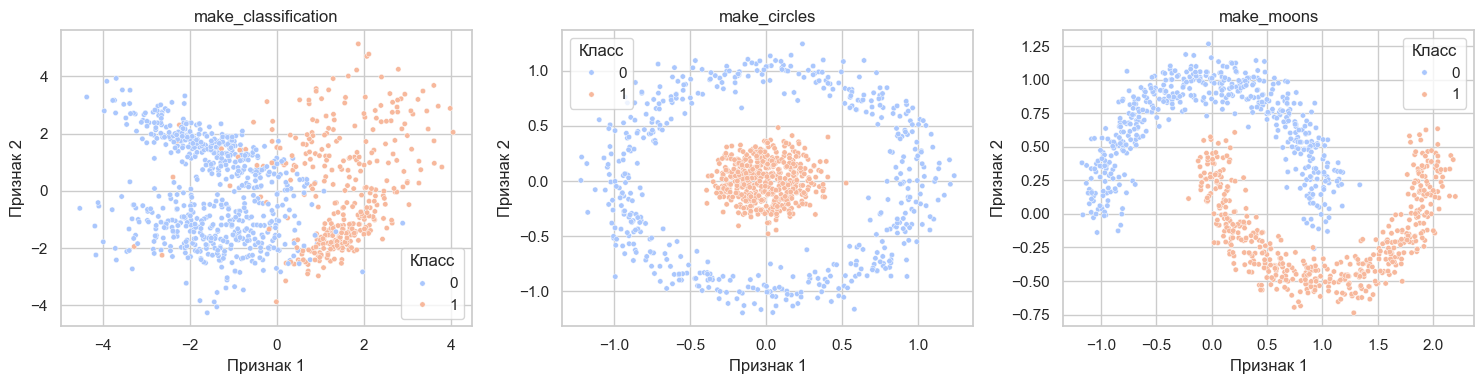

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (X, y)) in zip(axes, toy_data.items()):
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y.astype(str), hue_order=['0', '1'], palette='coolwarm', s=15, ax=ax)
    ax.set(title=name, xlabel='Признак 1', ylabel='Признак 2')
    ax.legend(title='Класс')
fig.tight_layout()
save_show(fig, '01_toy_data.png')

Точка — один учебный объект, цвет — его класс. У окружностей один класс находится внутри другого; у полумесяцев две изогнутые группы. Одной прямой такие классы полностью не разделить. Эти формы удобны для сравнения гибкости нейронных сетей.

Откладываем проверочные точки одинаково для всех вариантов модели.

In [10]:
toy_splits = {}
for name, (X, y) in toy_data.items():
    train, test = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=SEED)
    toy_splits[name] = (train, test)

Обучаем сеть из примера на make_classification.

In [11]:
X_example, y_example = toy_data['make_classification']
train_example, test_example = toy_splits['make_classification']
example = make_mlp((10, 20, 20, 10)).fit(X_example[train_example], y_example[train_example])
print('Обучающих точек:', len(train_example), '| Проверочных:', len(test_example))
print('Accuracy проверки:', accuracy_score(y_example[test_example], example.predict(X_example[test_example])))
print('Итераций:', example.named_steps['mlp'].n_iter_)
print('Ответы для точек из примера:', example.predict([[1.0, 2.0], [-4.0, 0.0], [-3.1, 2.2]]))

Обучающих точек: 700 | Проверочных: 300
Accuracy проверки: 0.96
Итераций: 385
Ответы для точек из примера: [1 0 0]


Показываем границу сети и изменение потерь при обучении.

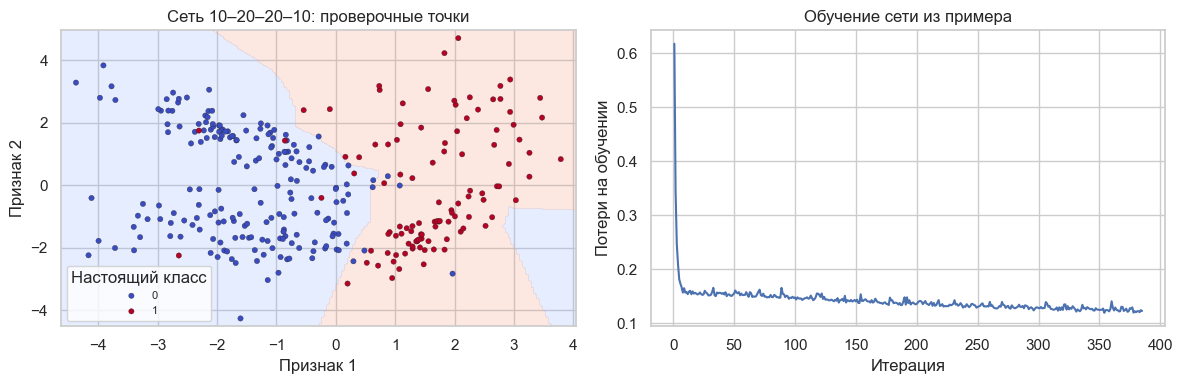

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw_boundary(axes[0], example.predict, X_example[test_example], y_example[test_example], 'Сеть 10–20–20–10: проверочные точки')
axes[1].plot(np.arange(1, len(example.named_steps['mlp'].loss_curve_) + 1), example.named_steps['mlp'].loss_curve_)
axes[1].set(title='Обучение сети из примера', xlabel='Итерация', ylabel='Потери на обучении')
fig.tight_layout()
save_show(fig, '02_example_boundary_loss.png')

Цветной фон показывает ответ сети в каждой точке плоскости, а точки — настоящие классы отложенных объектов. Несовпадение цвета фона и точки означает ошибку. Справа показаны потери обучения: их уменьшение говорит, что сеть подбирает веса, но само по себе не доказывает качество на новых точках.

## 3. Индивидуальное задание
### 3.1. Наборы разной природы и архитектуры — пункты 1–2
Сравниваем один скрытый слой из 4 или 20 нейронов, два слоя 20–20 и четыре слоя 10–20–20–10. Прочие настройки одинаковы. Для каждого набора обучающие и проверочные точки одни и те же. Таблица показывает обе accuracy и число итераций.

Обучаем четыре архитектуры на каждом наборе.

In [13]:
architectures = [(4,), (20,), (20, 20), (10, 20, 20, 10)]
architecture_models, architecture_rows = {}, []
for name, (X, y) in toy_data.items():
    train, test = toy_splits[name]
    for layers in architectures:
        label = '–'.join(map(str, layers))
        model = make_mlp(layers).fit(X[train], y[train])
        architecture_models[(name, label)] = model
        architecture_rows.append({'dataset': name, 'layers': label,
            'train_accuracy': accuracy_score(y[train], model.predict(X[train])),
            'test_accuracy': accuracy_score(y[test], model.predict(X[test])),
            'iterations': model.named_steps['mlp'].n_iter_})
architecture_table = pd.DataFrame(architecture_rows)
display(architecture_table)

,dataset,layers,train_accuracy,test_accuracy,iterations
0,make_classification,4,0.934286,0.953333,108
1,make_classification,20,0.951429,0.960000,224
2,make_classification,20–20,0.957143,0.953333,598
3,make_classification,10–20–20–10,0.955714,0.960000,385
4,make_circles,4,0.700000,0.680000,285
5,make_circles,20,1.000000,1.000000,92
6,make_circles,20–20,1.000000,1.000000,50
7,make_circles,10–20–20–10,1.000000,1.000000,38
8,make_moons,4,0.892857,0.903333,274
9,make_moons,20,1.000000,0.996667,162


Сравниваем области решения разных архитектур.

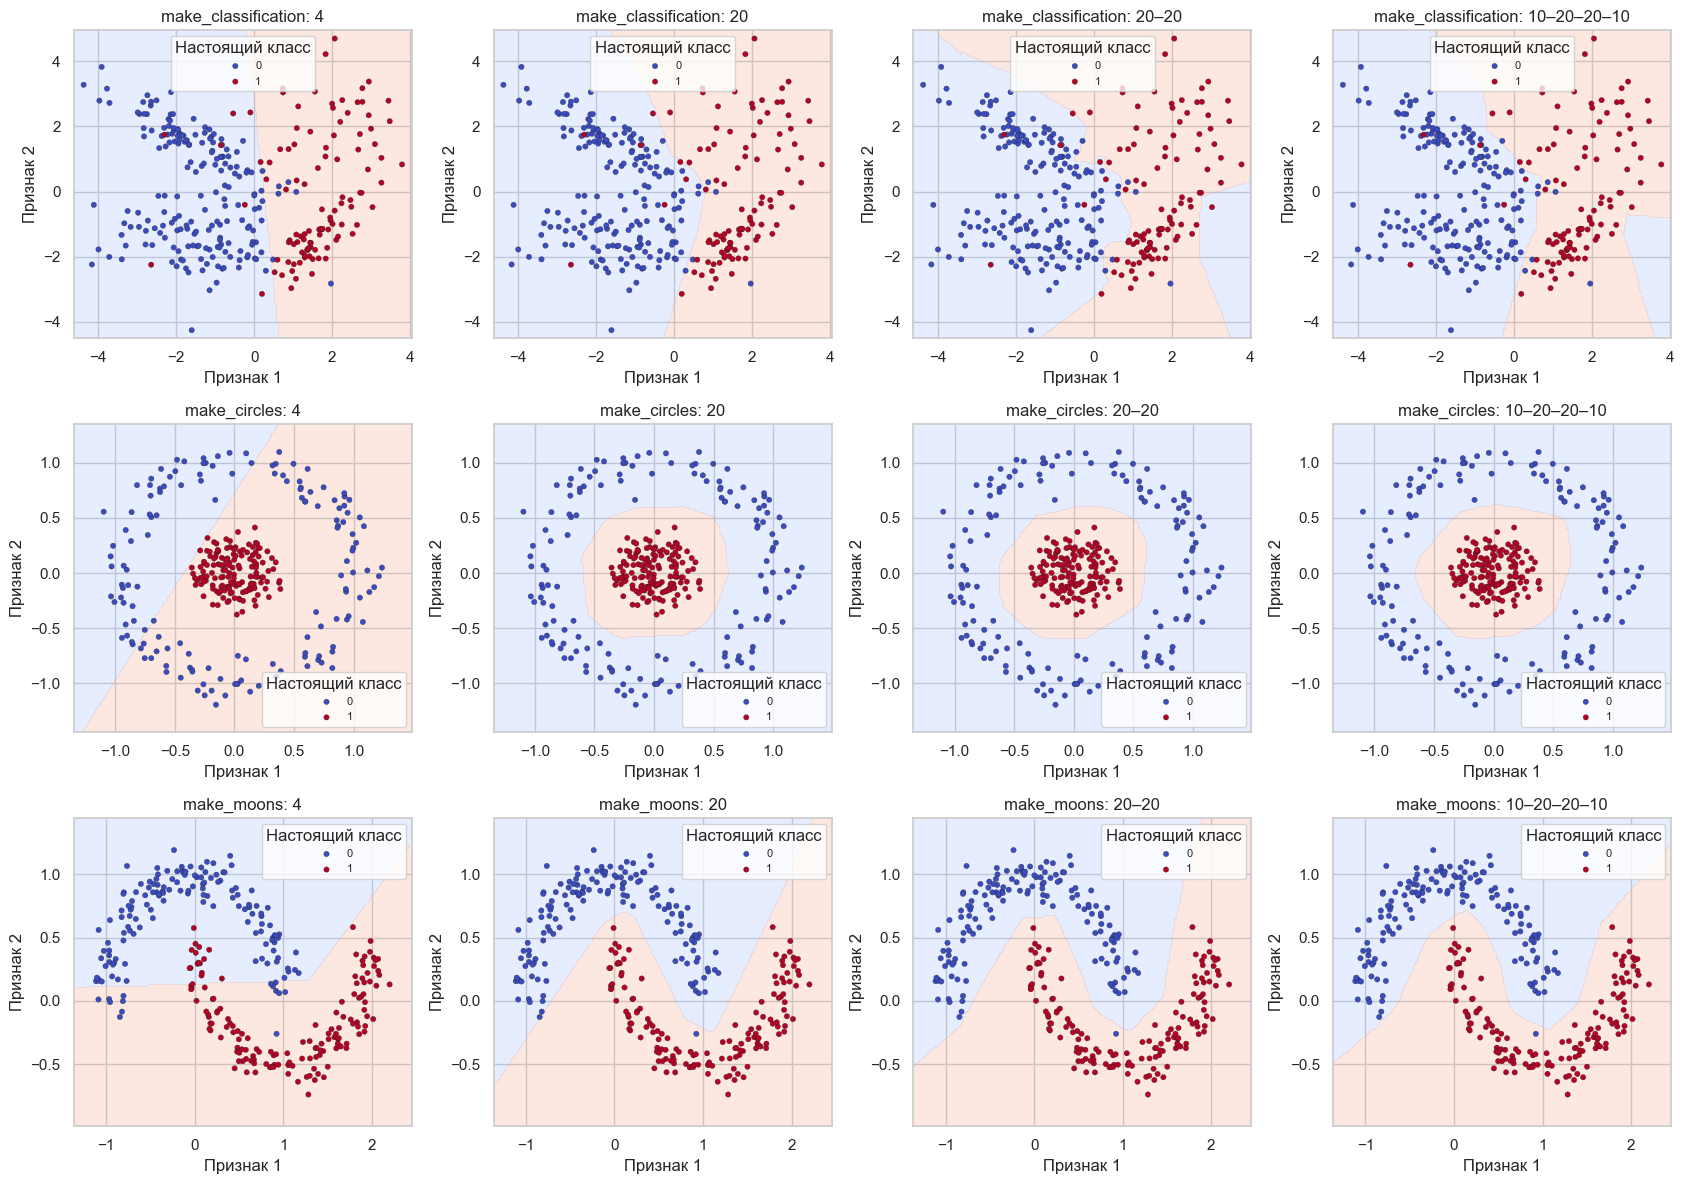

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(17, 12))
for row, (name, (X, y)) in enumerate(toy_data.items()):
    _, test = toy_splits[name]
    for col, layers in enumerate(architectures):
        label = '–'.join(map(str, layers))
        draw_boundary(axes[row, col], architecture_models[(name, label)].predict,
                      X[test], y[test], f'{name}: {label}')
fig.tight_layout()
save_show(fig, '03_architecture_boundaries.png')

В каждой строке один набор и одни проверочные точки; по столбцам меняется только архитектура. Так видно, хватает ли сети гибкости для окружности и полумесяца. Больше слоёв не обязательно означает лучшее разделение: результат зависит от обучения, шума и конкретных начальных весов. Это сравнение на одном разбиении, а не доказательство превосходства архитектуры во всех задачах.

### 3.2. Оптимизаторы одной архитектуры — пункт 3
Фиксируем скрытые слои 20–20 и сравниваем `lbfgs`, `sgd`, `adam`. Шаг для SGD и Adam одинаков — 0,01; L-BFGS использует собственный выбор шага. У него нет такой же истории эпох `loss_curve_`. Число итераций разных оптимизаторов не означает одинаковый объём вычислений.

Обучаем одну архитектуру тремя оптимизаторами.

In [15]:
solver_models, solver_rows = {}, []
for name, (X, y) in toy_data.items():
    train, test = toy_splits[name]
    for solver in ['lbfgs', 'sgd', 'adam']:
        model = make_mlp((20, 20), solver).fit(X[train], y[train])
        solver_models[(name, solver)] = model
        solver_rows.append({'dataset': name, 'solver': solver,
            'train_accuracy': accuracy_score(y[train], model.predict(X[train])),
            'test_accuracy': accuracy_score(y[test], model.predict(X[test])),
            'iterations': model.named_steps['mlp'].n_iter_})
solver_table = pd.DataFrame(solver_rows)
display(solver_table)

,dataset,solver,train_accuracy,test_accuracy,iterations
0,make_classification,lbfgs,0.968571,0.950000,1036
1,make_classification,sgd,0.950000,0.966667,332
2,make_classification,adam,0.957143,0.953333,598
3,make_circles,lbfgs,1.000000,1.000000,14
4,make_circles,sgd,1.000000,1.000000,97
5,make_circles,adam,1.000000,1.000000,50
6,make_moons,lbfgs,1.000000,0.996667,22
7,make_moons,sgd,1.000000,0.996667,188
8,make_moons,adam,1.000000,0.996667,67


Сравниваем области решения разных оптимизаторов.

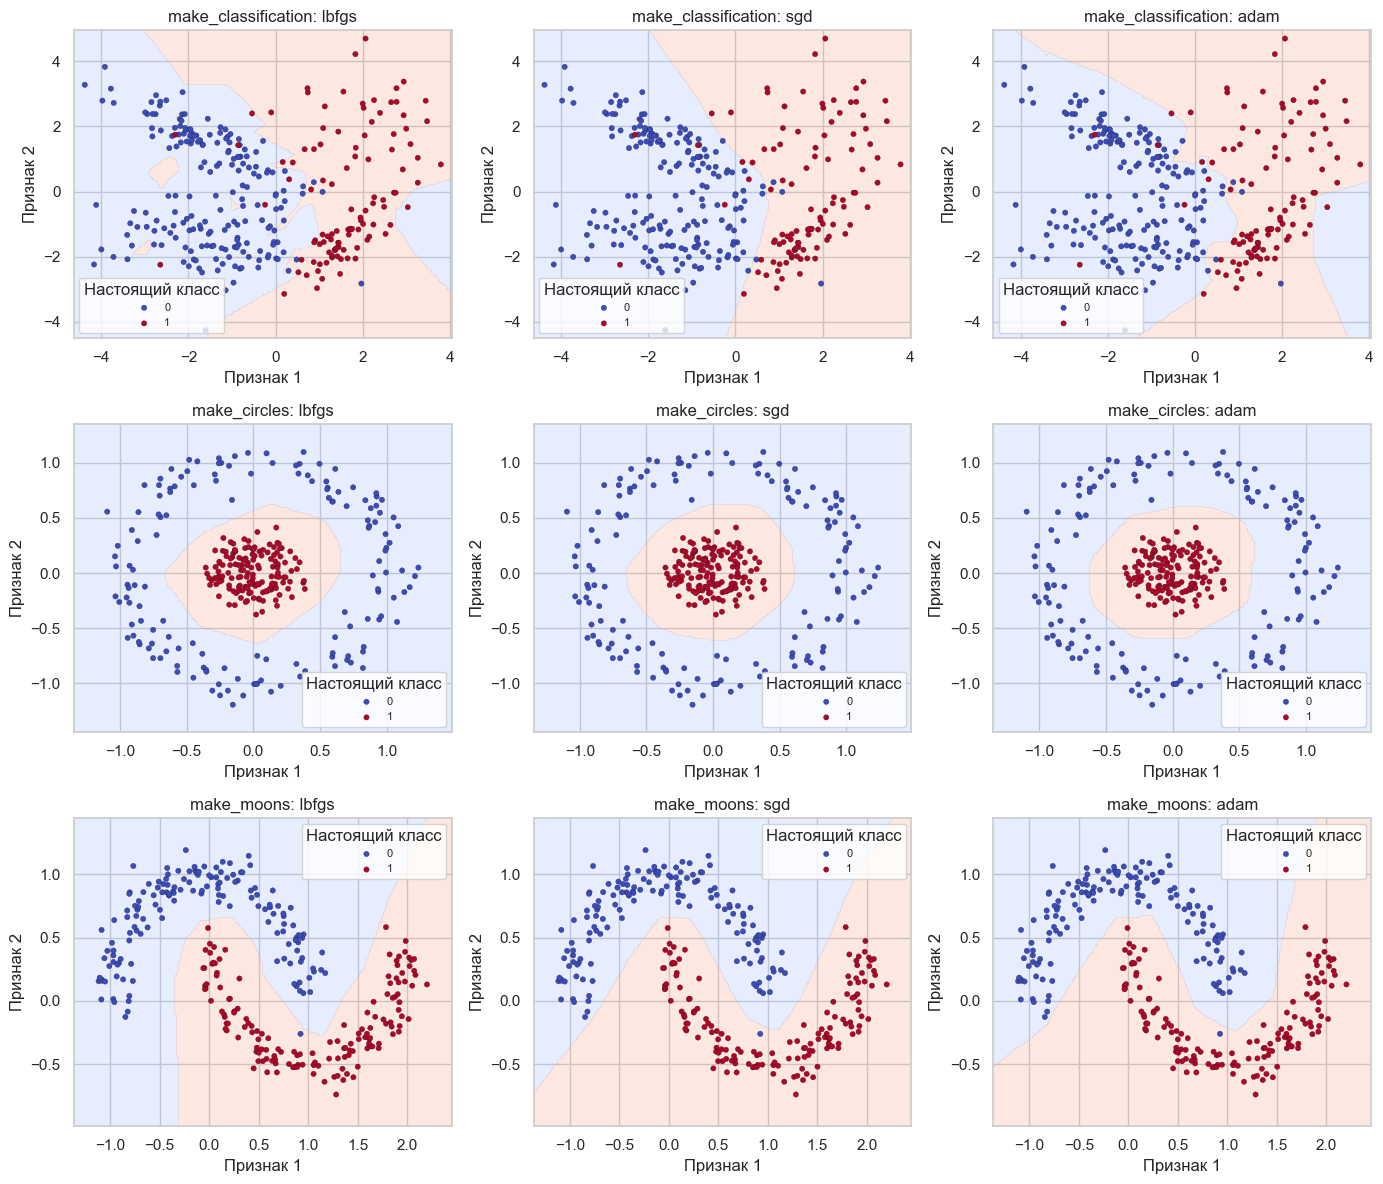

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for row, (name, (X, y)) in enumerate(toy_data.items()):
    _, test = toy_splits[name]
    for col, solver in enumerate(['lbfgs', 'sgd', 'adam']):
        draw_boundary(axes[row, col], solver_models[(name, solver)].predict,
                      X[test], y[test], f'{name}: {solver}')
fig.tight_layout()
save_show(fig, '04_optimizer_boundaries.png')

Архитектура одинакова, но пути изменения весов различаются, поэтому границы могут отличаться. Сравниваем ошибки на тех же проверочных точках и форму областей. Для другого шага или seed результат может измениться; один запуск не определяет лучший оптимизатор вообще.

### 3.3. Дополнение по теме мониторинга: прежний RCAEval
Обязательные пункты методички выполнены на синтетических наборах. Для связи с темой исследования дополнительно применяем MLP к прежним реальным метрикам. Задача — определить период до/начиная с внесения CPU stress, а не распознать любой возможный сбой.

Читаем локальные метрики и момент внесения сбоя.

In [17]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case_dir = ROOT / 'data/raw/rcaeval' / selection['case']
metrics_path, inject_path = case_dir / 'metrics.parquet', case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text().strip())

Выбираем настоящие метрики и показываем первые строки.

In [18]:
features = ['checkoutservice_cpu', 'checkoutservice_mem', 'checkoutservice_socket',
            'checkoutservice_workload', 'checkoutservice_latency-50']
X_rca = df[features]
y_rca = (df.time >= inject_time).astype(int)
groups = ((df.time - df.time.min()) // 60).astype(int)
display(X_rca.head())
print('Исходная таблица:', df.shape, '| Вход модели:', X_rca.shape)

,checkoutservice_cpu,checkoutservice_mem,checkoutservice_socket,checkoutservice_workload,checkoutservice_latency-50
0,0.215886,11702272.0,9.0,0.8,0.243182
1,0.380058,11706368.0,9.0,1.0,0.299999
2,0.380058,11706368.0,9.0,1.0,0.299999
3,0.380058,11706368.0,9.0,1.0,0.299999
4,0.380058,11706368.0,9.0,1.0,0.299999


Исходная таблица: (1441, 73) | Вход модели: (1441, 5)


Откладываем целые минуты и сравниваем архитектуры только на обучении.

In [19]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_rca, test_rca = next(outer.split(X_rca, y_rca, groups))
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rca_rows = []
for layers in [(4,), (20,), (20, 20)]:
    scores = cross_val_score(make_mlp(layers), X_rca.iloc[train_rca], y_rca.iloc[train_rca],
                            groups=groups.iloc[train_rca], cv=cv, scoring='accuracy')
    rca_rows.append({'layers': layers, 'CV_accuracy': scores.mean()})
rca_cv = pd.DataFrame(rca_rows)
display(rca_cv)

,layers,CV_accuracy
0,"(4,)",0.988333
1,"(20,)",0.959167
2,"(20, 20)",0.976667


Записи одной минуты не разделяются между обучением и проверкой. В CV подготовка и веса каждый раз обучаются заново. Выбираем максимальную среднюю accuracy, при равенстве — первый, более простой вариант таблицы. Время и метка периода во входные признаки не входят.

Обучаем выбранную архитектуру и проверяем на отложенных минутах.

In [20]:
best_layers = rca_rows[int(rca_cv.CV_accuracy.idxmax())]['layers']
rca_model = make_mlp(best_layers).fit(X_rca.iloc[train_rca], y_rca.iloc[train_rca])
rca_prediction = rca_model.predict(X_rca.iloc[test_rca])
rca_accuracy = accuracy_score(y_rca.iloc[test_rca], rca_prediction)
print('Архитектура:', best_layers, '| Accuracy:', rca_accuracy, '| Проверочных строк:', len(test_rca))

Архитектура: (4,) | Accuracy: 1.0 | Проверочных строк: 300


Показываем ошибки и обучение модели мониторинга.

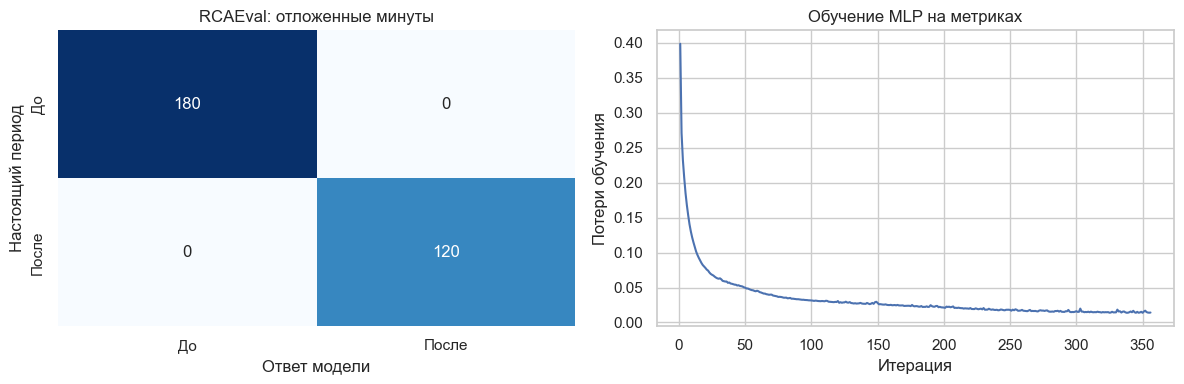

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_rca.iloc[test_rca], rca_prediction), annot=True, fmt='d', cmap='Blues',
            cbar=False, xticklabels=['До', 'После'], yticklabels=['До', 'После'], ax=axes[0])
axes[0].set(title='RCAEval: отложенные минуты', xlabel='Ответ модели', ylabel='Настоящий период')
axes[1].plot(np.arange(1, len(rca_model.named_steps['mlp'].loss_curve_) + 1), rca_model.named_steps['mlp'].loss_curve_)
axes[1].set(title='Обучение MLP на метриках', xlabel='Итерация', ylabel='Потери обучения')
fig.tight_layout()
save_show(fig, '05_rca_confusion_loss.png')

На диагонали матрицы — правильно определённые периоды, вне диагонали — ошибки. Справа потери относятся только к обучению. Хороший результат одного CPU-эксперимента не показывает, как сеть распознает другой сервис или новый тип неисправности.

Сохраняем таблицы и формируем простой текст результата.

In [22]:
architecture_table.to_csv(REPORT / 'architecture_comparison.csv', index=False)
solver_table.to_csv(REPORT / 'optimizer_comparison.csv', index=False)
rca_cv.to_csv(REPORT / 'rca_cv.csv', index=False)
pd.DataFrame({'row': test_rca, 'actual': y_rca.iloc[test_rca].to_numpy(),
              'prediction': rca_prediction}).to_csv(REPORT / 'rca_predictions.csv', index=False)
analysis = (f'Научился применять MLPClassifier для классификации. Сравнил четыре архитектуры '
            f'и три оптимизатора на трёх учебных наборах. На прежнем RCAEval по CV выбраны '
            f'скрытые слои {best_layers}; на {len(test_rca)} отложенных строках верно определено '
            f'{rca_accuracy:.1%} периодов. Результат относится к одному эксперименту.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
summary = {'case': selection['case'], 'best_layers': best_layers, 'rca_test_rows': len(test_rca),
           'rca_accuracy': rca_accuracy, 'architecture_results': architecture_table.to_dict('records'),
           'optimizer_results': solver_table.to_dict('records'),
           'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
sources = {'example_revision': 'a282e5ed90a613dbf4806e1c572240d919164a72',
           'rcaeval': selection, 'sha256': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                                          for p in [metrics_path, inject_path]}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

Научился применять MLPClassifier для классификации. Сравнил четыре архитектуры и три оптимизатора на трёх учебных наборах. На прежнем RCAEval по CV выбраны скрытые слои (4,); на 300 отложенных строках верно определено 100.0% периодов. Результат относится к одному эксперименту.

938

## 4. Заключение
Научился применять простейшую модель искусственной нейронной сети для решения задачи классификации. Использовал MLPClassifier, изучил изменение потерь при обучении, сравнил число слоёв, нейронов и способы оптимизации.

Построил области решений на окружностях, полумесяцах и make_classification. Дополнительно проверил MLP на прежних метриках мониторинга. Увидел, что увеличение сети само по себе не гарантирует лучших ответов: результат нужно проверять на отдельных данных.



## 5. Ответы на контрольные вопросы
**1. Как устроен многослойный персептрон?**  
Входные признаки поступают в один или несколько скрытых слоёв, затем в выходной слой. В полносвязной сети каждый нейрон слоя получает результаты всех нейронов предыдущего слоя. Скрытые активации дают нелинейность.

**2. Как устроен нейрон и как это задаётся в MLPClassifier?**  
Нейрон считает сумму «признак × вес», добавляет смещение и применяет активацию. `hidden_layer_sizes` задаёт число нейронов скрытых слоёв, `activation` — их активацию. Веса и смещения появляются после обучения в `coefs_` и `intercepts_`. В бинарном выходе используется логистическая функция, при нескольких классах — softmax; параметр `activation` меняет скрытые слои.

**3. Как выбрать оптимизатор?**  
Параметром `solver`: `lbfgs`, `sgd` или `adam`. SGD обновляет веса по градиенту, Adam подстраивает шаг для весов, L-BFGS использует приближение информации о кривизне функции потерь.

**4. Как выбрать активацию?**  
Параметром `activation`: `identity`, `logistic`, `tanh`, `relu`. Без нелинейной активации несколько линейных слоёв остаются одним линейным преобразованием.

**5. Что задаёт make_classification?**  
`n_samples` — число строк; `n_features` — число признаков; `n_informative` — полезные признаки; `n_redundant` — их линейные комбинации; `n_repeated` — копии. `n_classes` — классы, `n_clusters_per_class` — группы внутри класса, `weights` — доли классов, `class_sep` — разделение групп, `flip_y` — случайные изменения меток, `random_state` — повторяемость.

**6. Какие основные настройки есть у MLPClassifier?**  
`hidden_layer_sizes` задаёт скрытые слои, `activation` — активацию, `solver` — оптимизатор. `learning_rate_init` — начальный шаг, `learning_rate` — правило шага SGD, `alpha` — штраф за большие веса, `batch_size` — число строк в порции, `max_iter` — предел итераций, `tol` и `n_iter_no_change` — остановку, `early_stopping` — отдельную проверку для остановки, `random_state` — начальные веса и случайные операции.
